# Safe to operate: random loss rates (200k runs)

**Question.** Does the convergence behaviour change when the loss rates differ from run to run?

**Data.** `STO-random_decay-200k.csv`, generated by `generate_STO_random_decay.py` with the Python simulator
`Tools/esc_sim.py` (it reproduces the MATLAB datasets exactly, see `Tools/validate_esc_sim.py`).
It is the experiment of `STO_ESC_randdecay.m`: 200,000 runs of 100 s, ESC parameters drawn as in the
constant-loss sweep, and the confinement times drawn per run, $\tau_D = 1.71 \pm 0.1$ s and
$\tau_T = 1.66 \pm 0.1$ s (uniform). The estimate $\hat r$ starts at 0.

This dataset replaces the earlier 10k random-decay sweep, which was generated with deuterium and tritium
fuelling swapped and without storing the loss rates.

## 1. Setup

In [1]:
# Shared tools (plot style, model constants, averaged-ESC formulas) live in Tools/ at the repository root
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import esc_tools as esc

esc.apply_style()   # one plot style for every notebook in this repository

In [2]:
df = pd.read_csv('STO-random_decay-200k.csv')
const = pd.read_csv('../STO-const_decay/STO-const_decay-200k.csv')   # constant-loss sweep, for comparison
print(f'{len(df):,} runs, {df.shape[1]} columns')
df.head()

200,000 runs, 8 columns


,optimizer_gain,dither_amplitude,dither_frequency,n_D_decay_rate,n_T_decay_rate,ideal_ratio,converged,convergence_time
0,0.000105,0.327414,6.304293,0.555597,0.574698,0.508449,0,NaN
1,0.044345,0.735966,1.755244,0.571464,0.610713,0.516600,1,22.79
2,0.004602,0.790485,3.155422,0.561151,0.580952,0.508669,0,NaN
3,0.001293,0.289143,2.460245,0.564471,0.588794,0.510545,0,NaN
4,0.001054,0.694540,3.491478,0.556570,0.615596,0.525178,0,NaN


## 2. Data overview

In [3]:
overview = pd.DataFrame({'type': df.dtypes.astype(str), 'missing': df.isna().sum(), 'min': df.min(), 'max': df.max()})
print('convergence_time is missing exactly for the runs that did not converge:',
      bool((df['convergence_time'].isna() == (df['converged'] == 0)).all()))
overview

convergence_time is missing exactly for the runs that did not converge: True


,type,missing,min,max
optimizer_gain,float64,0,0.000010,4.999733
dither_amplitude,float64,0,0.000003,0.999998
dither_frequency,float64,0,0.000057,9.999888
n_D_decay_rate,float64,0,0.552486,0.621118
n_T_decay_rate,float64,0,0.568182,0.641026
ideal_ratio,float64,0,0.477811,0.537035
converged,int64,0,0.000000,1.000000
convergence_time,float64,130285,2.430000,95.010000


## 3. Convergence

#### Original plots

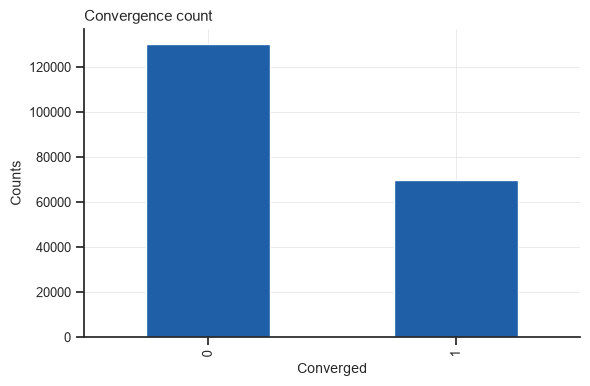

In [4]:
cv = df['converged'].value_counts().head(10).plot(kind = 'bar', title = 'Convergence count')

cv.set_xlabel('Converged')
cv.set_ylabel('Counts')
plt.show()

# Inspect the balance between converged and non-converged samples.

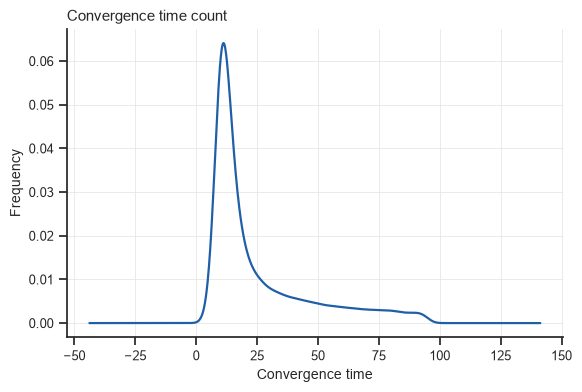

In [5]:
ct = df['convergence_time'].plot(kind = 'kde',
                title = 'Convergence time count')
ct.set_xlabel('Convergence time')
ct.set_ylabel('Frequency')
plt.show()

# Inspect the distribution of convergence times.

#### Added plots

69,715 of 200,000 runs converge (34.9%).
Convergence time: median 14.9 s, fastest 2.43 s.
Runs that converge in under 10 s: 11,770
Runs that converge in under 5 s: 204


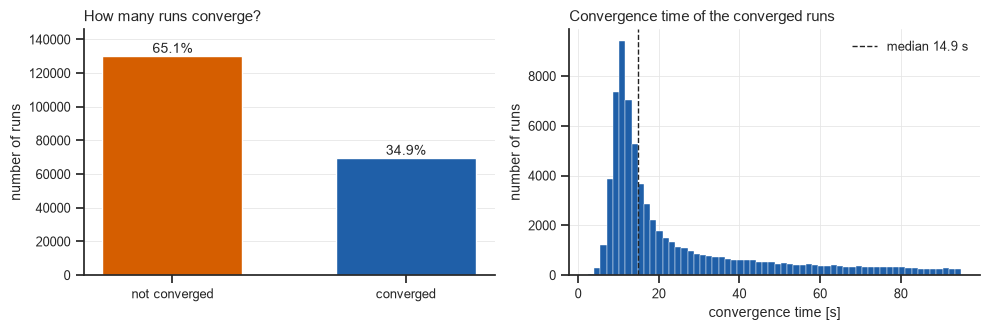

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
esc.outcome_bar(df['converged'], names=('not converged', 'converged'), title='How many runs converge?', ax=axes[0])
esc.time_hist(df['convergence_time'], title='Convergence time of the converged runs', ax=axes[1])
fig.tight_layout()
plt.show()

n_conv = int(df['converged'].sum())
print(f"{n_conv:,} of {len(df):,} runs converge ({n_conv / len(df):.1%}).")
print(f"Convergence time: median {df['convergence_time'].median():.1f} s, fastest {df['convergence_time'].min():.2f} s.")
for limit in (10, 5):
    print(f"Runs that converge in under {limit} s: {(df['convergence_time'] < limit).sum():,}")

### Effect of the random loss rates

The ideal ratio now differs between runs. The left panel shows its distribution; the right panel shows
whether the chance to converge depends on it. The printed line compares with the constant-loss sweep.

Converged: 34.9% with random loss rates, 36.9% with constant loss rates.
Median convergence time: 14.92 s (random), 14.40 s (constant).


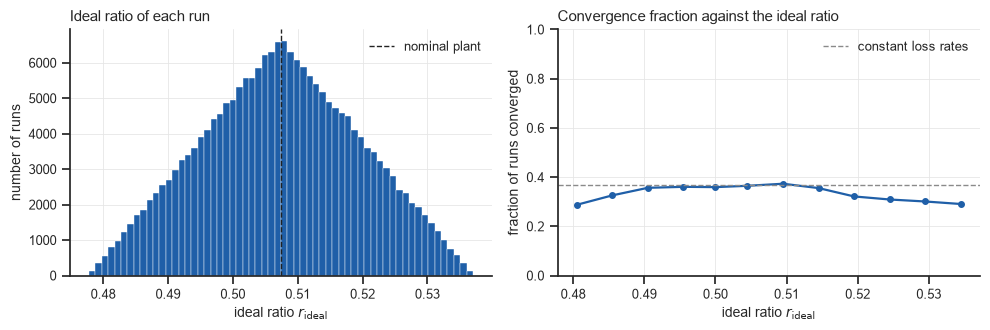

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(df['ideal_ratio'], bins=60, color=esc.COLORS['esc'], edgecolor='white', linewidth=0.3)
axes[0].axvline(esc.ALPHA_T / (esc.ALPHA_T + esc.ALPHA_D), color=esc.COLORS['ideal'], ls='--', lw=1, label='nominal plant')
axes[0].set_xlabel(esc.label('ideal_ratio')); axes[0].set_ylabel('number of runs')
axes[0].set_title('Ideal ratio of each run'); axes[0].legend()

by_ratio = df.groupby(pd.cut(df['ideal_ratio'], 12), observed=True)
centres = [iv.mid for iv in by_ratio.size().index]
axes[1].plot(centres, by_ratio['converged'].mean(), 'o-', color=esc.COLORS['esc'])
axes[1].axhline(const['converged'].mean(), color=esc.COLORS['grey'], ls='--', lw=1, label='constant loss rates')
axes[1].set_ylim(0, 1); axes[1].set_xlabel(esc.label('ideal_ratio')); axes[1].set_ylabel('fraction of runs converged')
axes[1].set_title('Convergence fraction against the ideal ratio'); axes[1].legend()
fig.tight_layout()
plt.show()

print(f"Converged: {df['converged'].mean():.1%} with random loss rates, {const['converged'].mean():.1%} with constant loss rates.")
print(f"Median convergence time: {df['convergence_time'].median():.2f} s (random), {const['convergence_time'].median():.2f} s (constant).")

## 4. Parameter relationships

### All converged runs

Only converged runs have a convergence time, so these plots show converged runs only.
The gain is drawn on a logarithmic axis because it was sampled log-uniformly.

#### Original plots

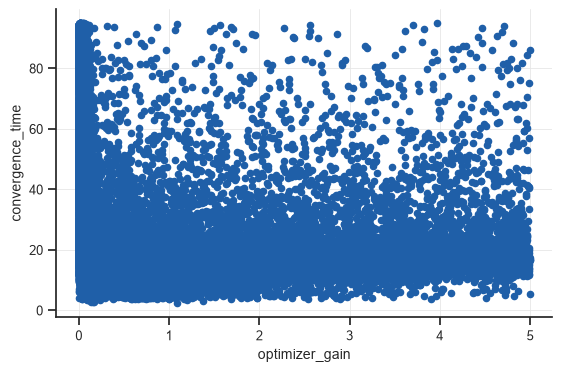

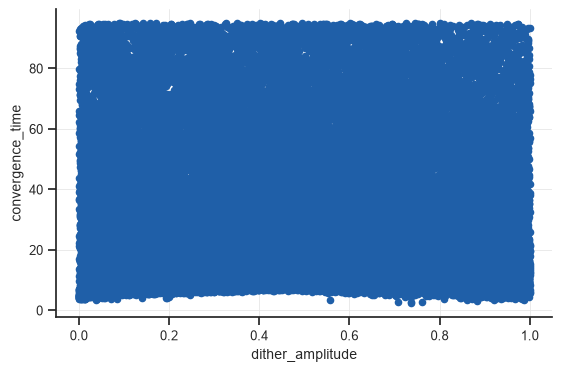

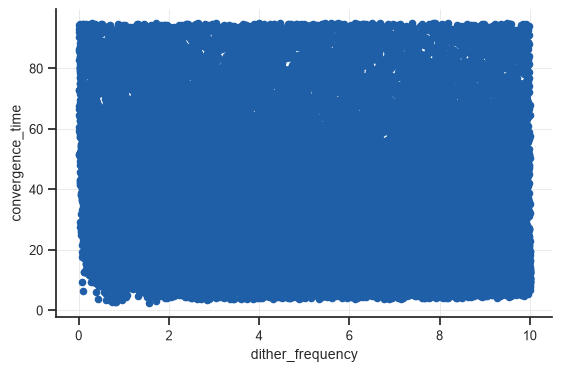

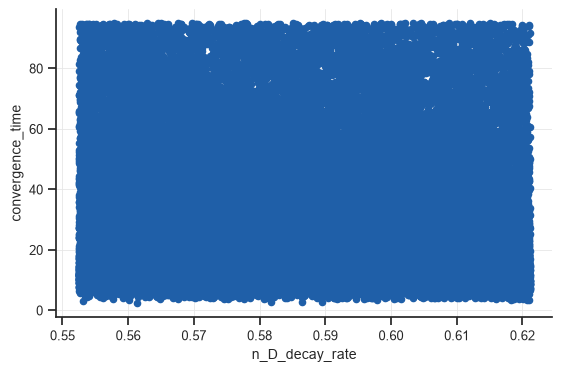

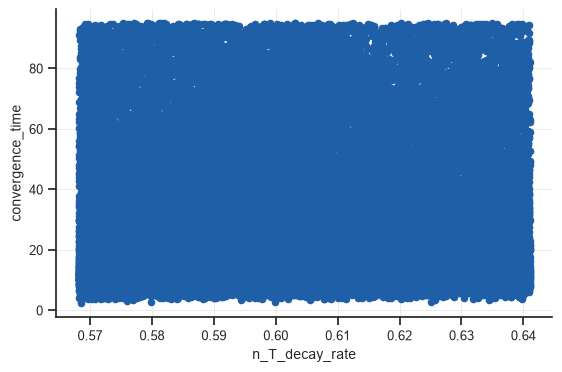

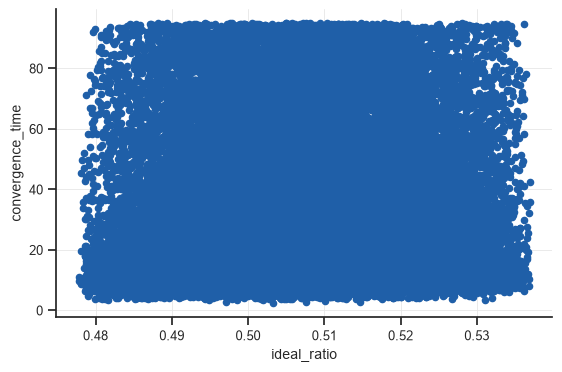

In [8]:
for i in range (df.shape[1] - 2):
    df.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()

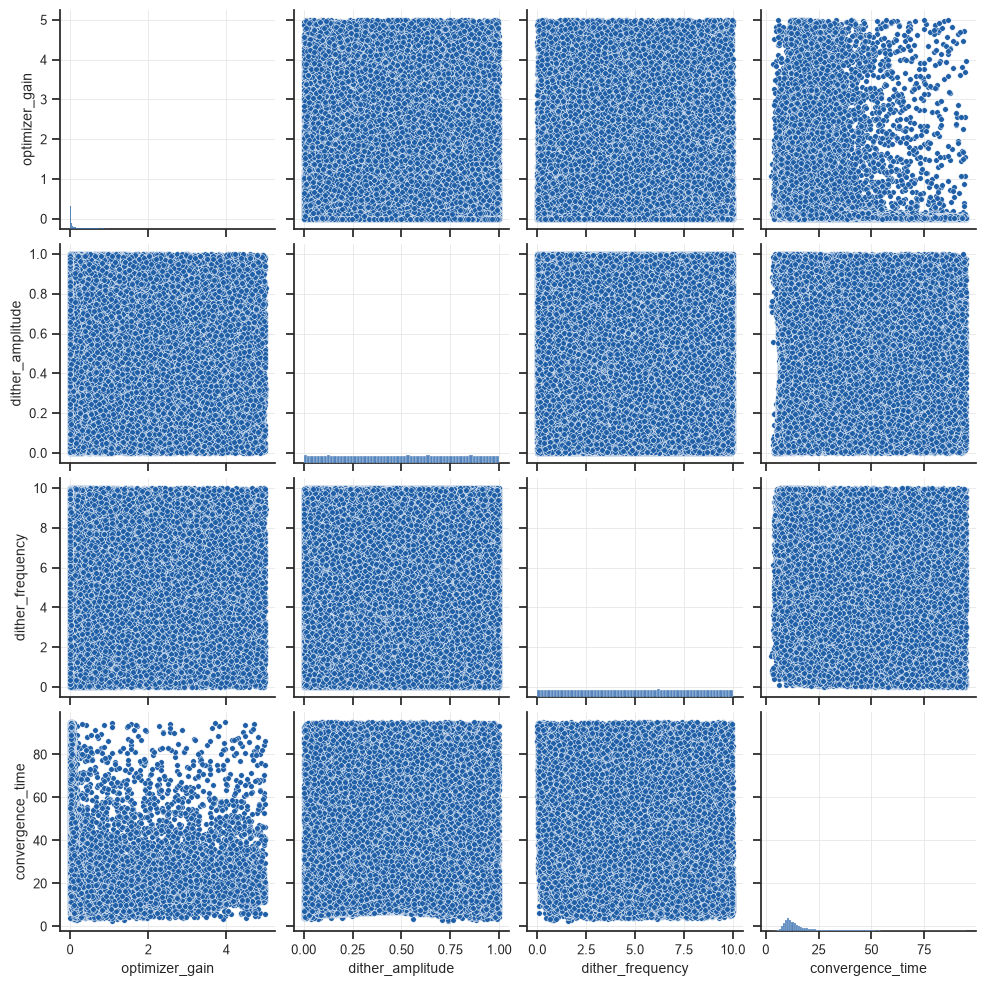

In [9]:
sns.pairplot(df,
             vars = ['optimizer_gain','dither_amplitude','dither_frequency', 'convergence_time'])
plt.show()

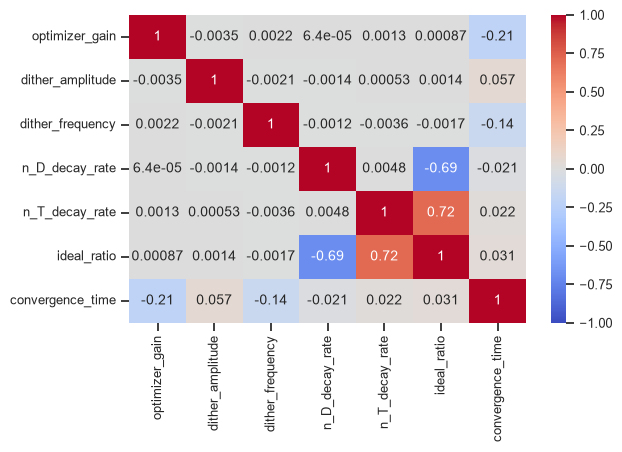

In [10]:
sns.heatmap(df.drop(columns = 'converged').corr(), annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1, center = 0)
plt.show()

#### Added plots (gain on a logarithmic axis, random samples)

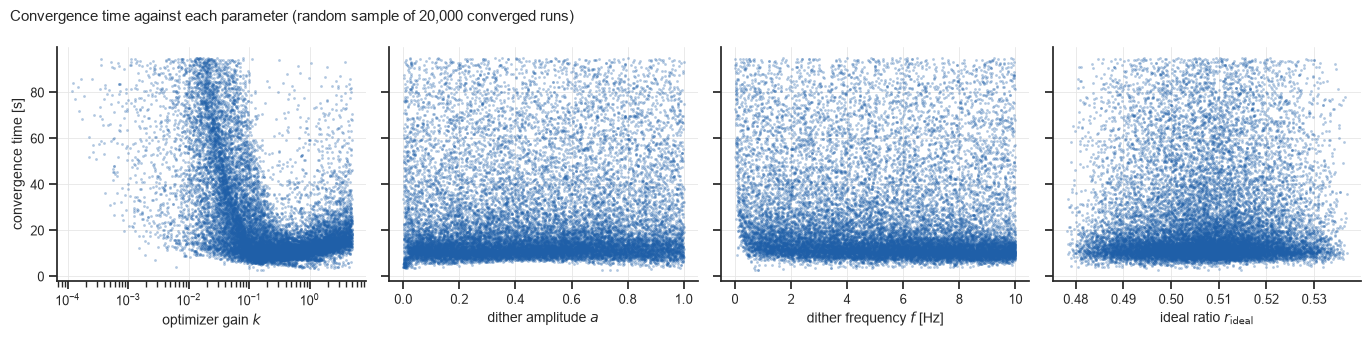

In [11]:
esc.scatter_grid(df, esc.ESC_PARAMS + ['ideal_ratio'], 'convergence_time',
                 title='Convergence time against each parameter (random sample of 20,000 converged runs)')
plt.show()

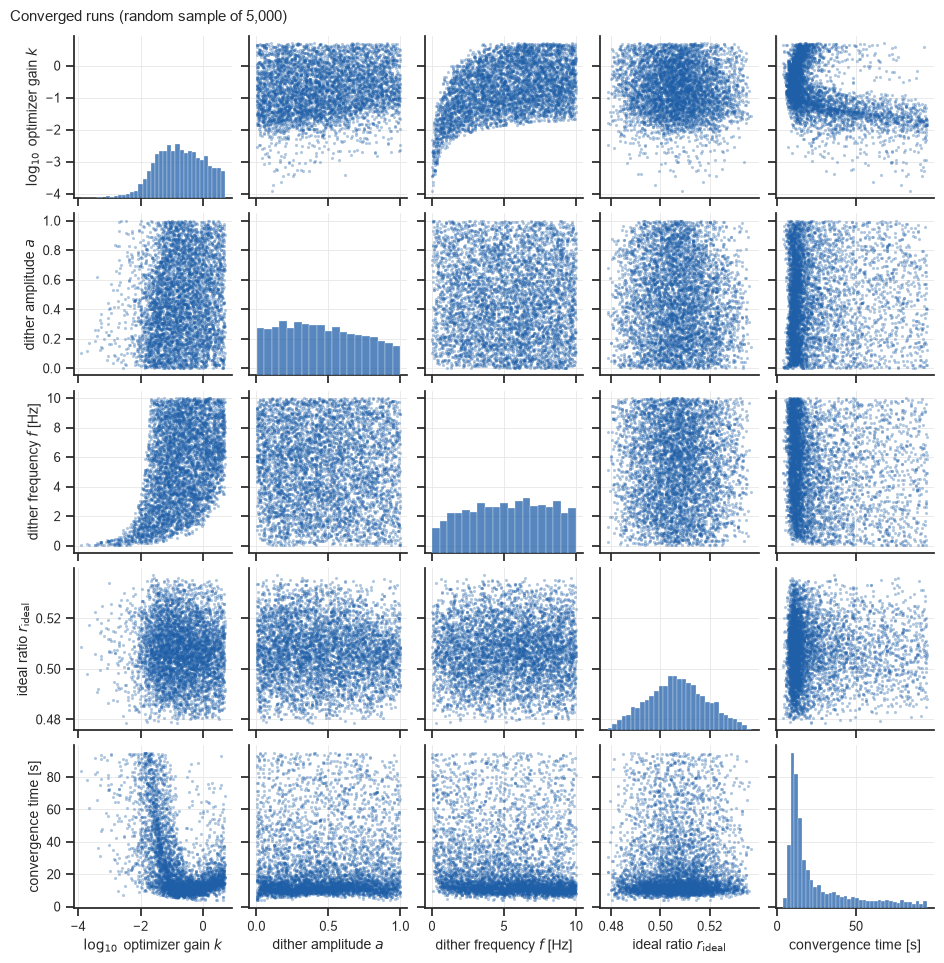

In [12]:
cols = esc.ESC_PARAMS + ['ideal_ratio'] + ['convergence_time']
esc.pair_plot(df, cols, title='Converged runs (random sample of 5,000)')
plt.show()

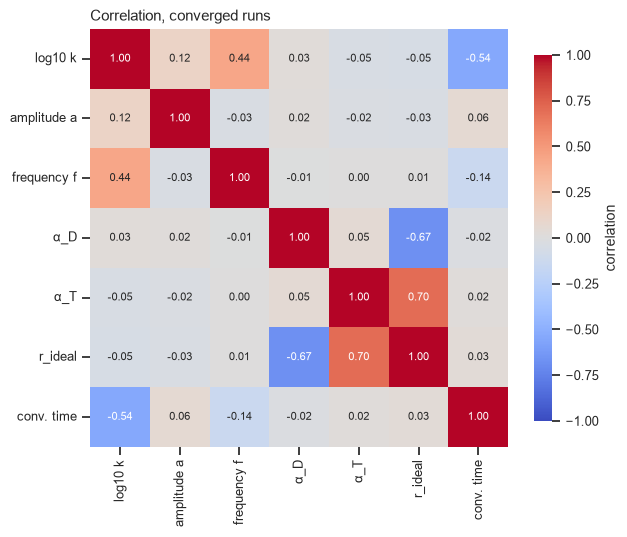

In [13]:
converged = df.dropna(subset=['convergence_time']).assign(log10_gain=lambda d: np.log10(d['optimizer_gain']))
heat_cols = ['log10_gain', 'dither_amplitude', 'dither_frequency', 'n_D_decay_rate', 'n_T_decay_rate', 'ideal_ratio', 'convergence_time']
esc.corr_heatmap(converged, heat_cols, title='Correlation, converged runs')
plt.show()

### Fast runs (convergence time under 10 s)

Gain and dither frequency are correlated among the converged runs, and more strongly among the fast ones:
a faster dither needs a larger gain. Section 5 explains this with the averaged convergence rate.

#### Original plots

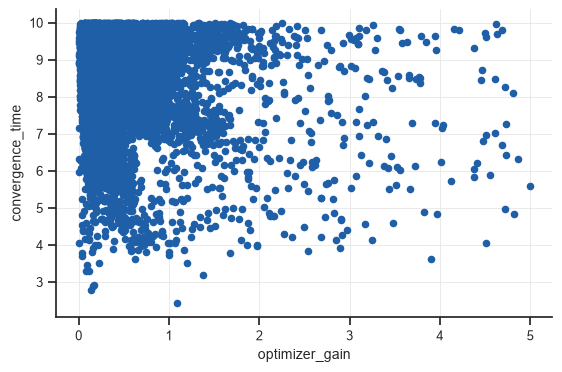

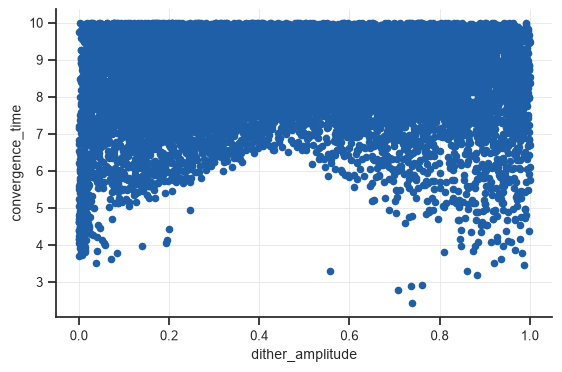

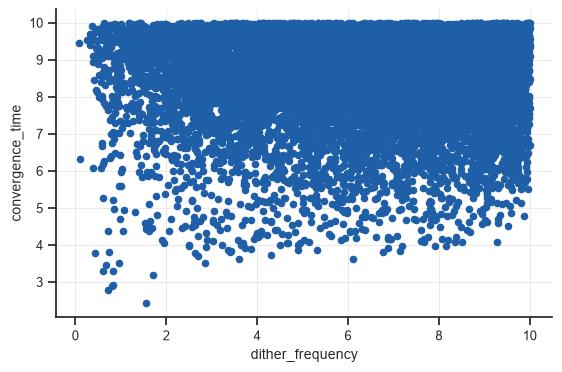

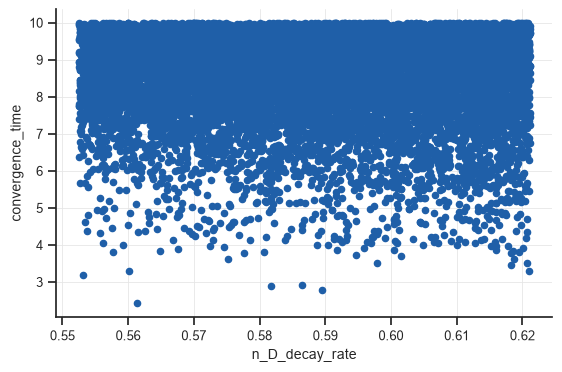

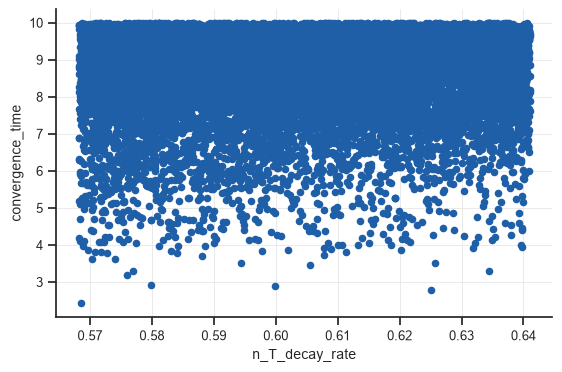

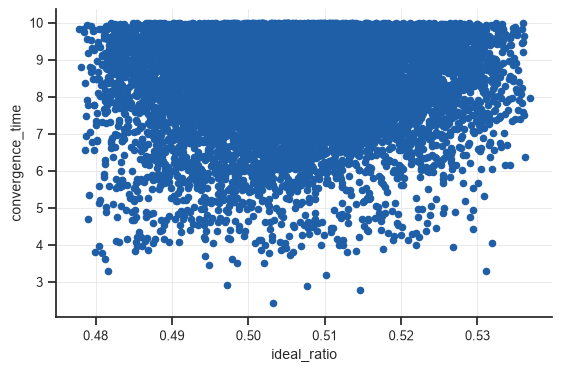

In [14]:
dfcut = df[df['convergence_time'] < 10]
for i in range (dfcut.shape[1] - 2):
    dfcut.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()

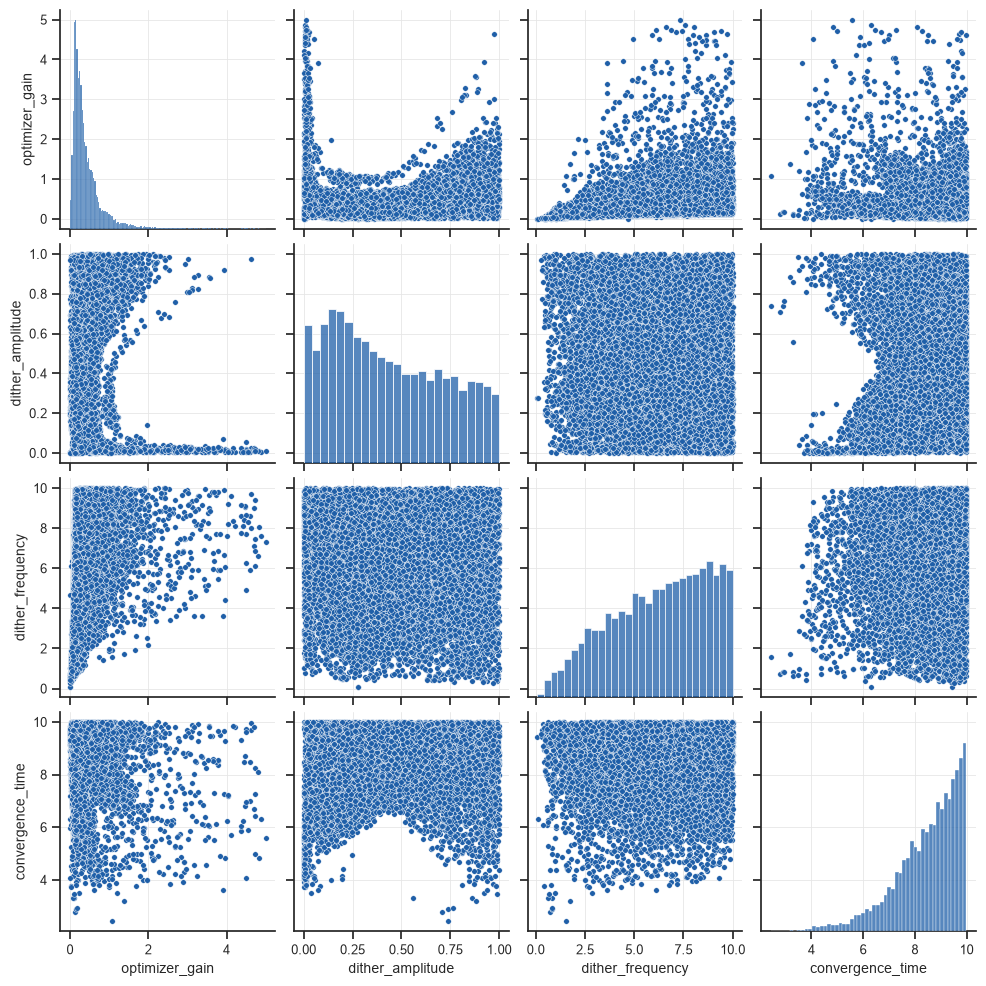

In [15]:
sns.pairplot(dfcut,
             vars = ['optimizer_gain','dither_amplitude','dither_frequency', 'convergence_time'])
plt.show()

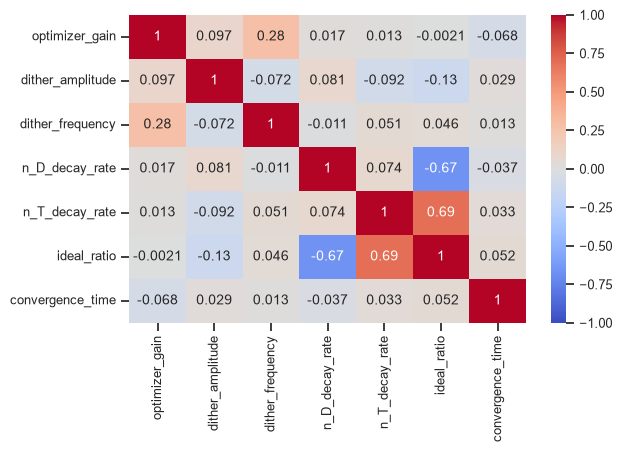

In [16]:
sns.heatmap(dfcut.drop(columns = 'converged').corr(), annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1, center = 0)
plt.show()

#### Added plots (gain on a logarithmic axis, random samples)

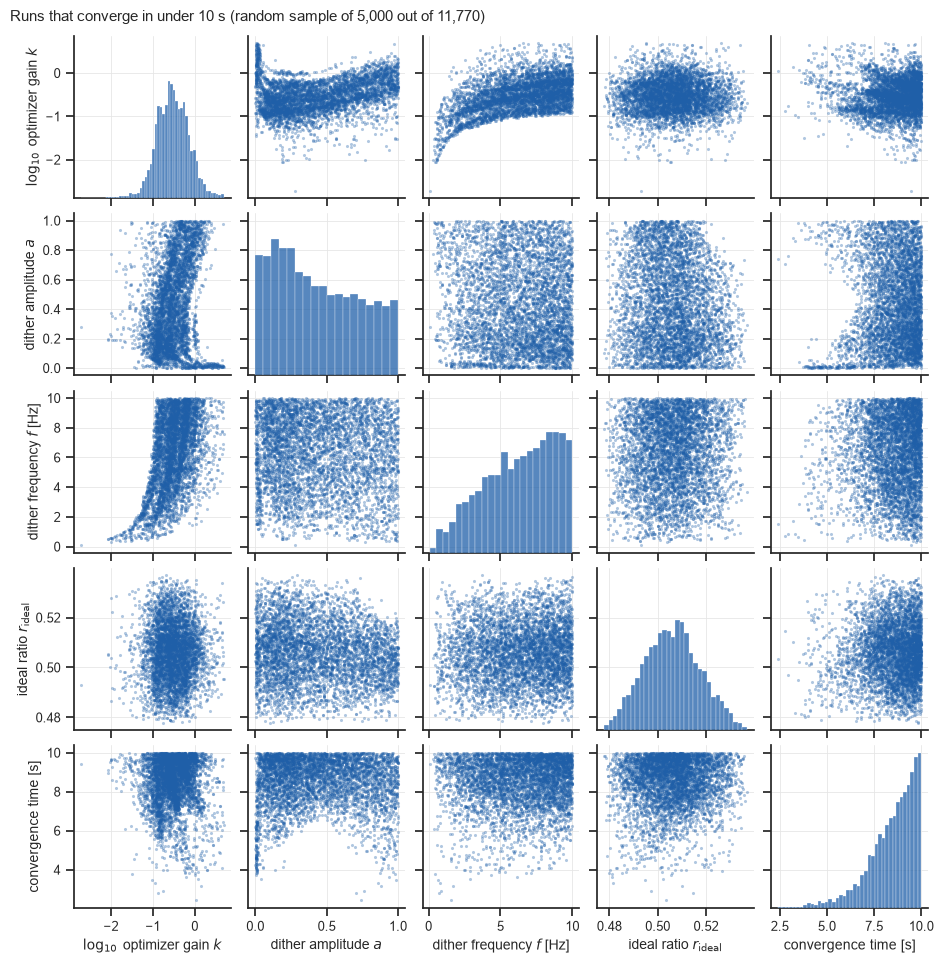

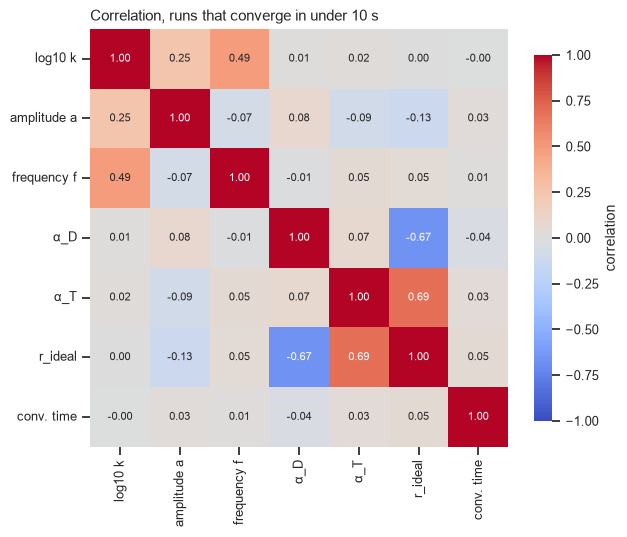

In [17]:
fast = converged[converged['convergence_time'] < 10]
esc.pair_plot(fast, cols, title=f'Runs that converge in under 10 s (random sample of 5,000 out of {len(fast):,})')
plt.show()
esc.corr_heatmap(fast, heat_cols, title='Correlation, runs that converge in under 10 s')
plt.show()

## 5. Averaged-ESC analysis

Each run is summarised by one number computed from its ESC parameters, the **averaged convergence rate**

$$\lambda_\mathrm{avg} = 2\,n_\mathrm{ref}^2\,k\,c(\omega),$$

where $c(\omega)$ is how much of the dither survives the plasma's low-pass response and the high-pass filter
(`esc.c_factor`). Averaging theory predicts $\dot{\hat r} \approx -\lambda_\mathrm{avg}(\hat r - r_\mathrm{ideal})$,
so the time to enter the 5 % band from $\hat r = 0$ is about $\ln 20/\lambda_\mathrm{avg}$.
The derivation is in the report (Section 3.2); it still has to be checked by the supervisor.

Here $\lambda_\mathrm{avg}$ uses each run's own mean loss rate. The grey curves are the constant-loss sweep.

Runs with 0.1 < lam_avg < 3.0 1/s: 51,453 of 200,000; converged: 91.1%


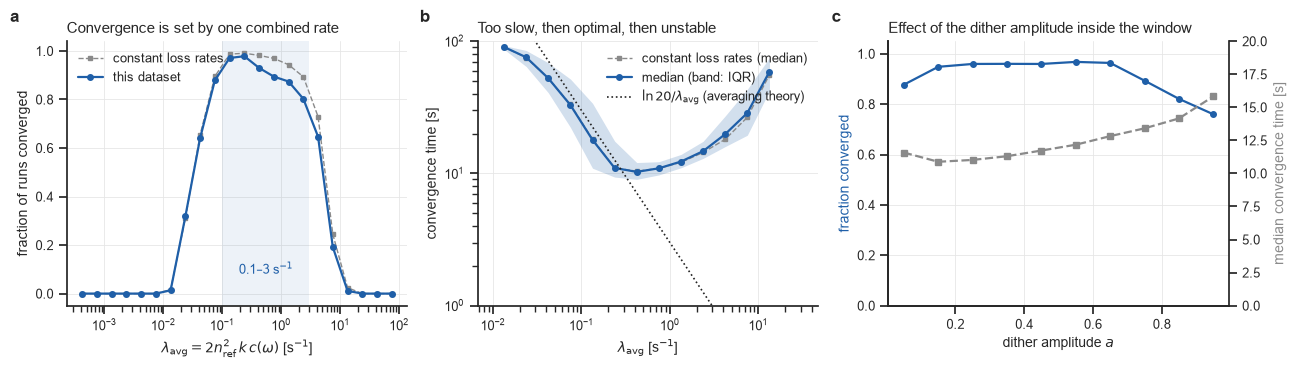

In [18]:
alpha_bar = 0.5 * (df['n_D_decay_rate'] + df['n_T_decay_rate'])    # mean loss rate of each run
fig, window = esc.convergence_vs_rate(df, alpha_bar=alpha_bar, others={'constant loss rates': const})
plt.show()
low, high = esc.LAM_WINDOW
print(f"Runs with {low} < lam_avg < {high} 1/s: {len(window):,} of {len(df):,}; converged: {window['converged'].mean():.1%}")

### Large dither amplitudes bias the estimate

Panel c above shows that, unlike in the constant-loss sweep, large dither amplitudes converge less often here.
The next plot splits the runs inside the window by amplitude and plots them against the ideal ratio.

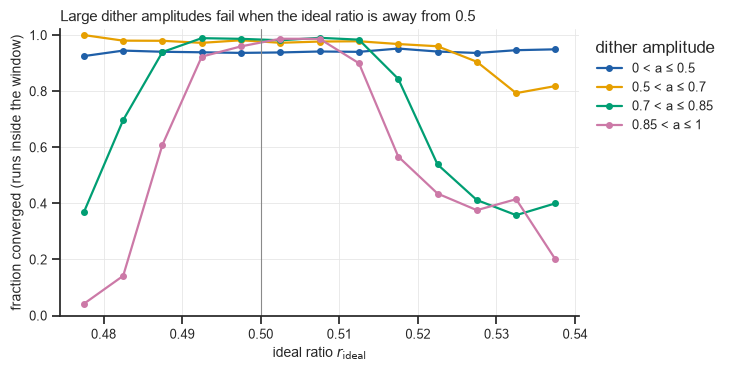

In [19]:
window = window.assign(amplitude=pd.cut(window['dither_amplitude'], [0, 0.5, 0.7, 0.85, 1.0]))
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for (group_name, group), color in zip(window.groupby('amplitude', observed=True), esc.CYCLE):
    by = group.groupby(pd.cut(group['ideal_ratio'], np.linspace(0.475, 0.540, 14)), observed=True)['converged'].mean()
    ax.plot([iv.mid for iv in by.index], by.values, 'o-', color=color, label=f'{group_name.left:g} < a ≤ {group_name.right:g}')
ax.axvline(0.5, color=esc.COLORS['grey'], lw=0.8)
ax.set_ylim(0, 1.02); ax.set_xlabel(esc.label('ideal_ratio')); ax.set_ylabel('fraction converged (runs inside the window)')
ax.set_title('Large dither amplitudes fail when the ideal ratio is away from 0.5')
ax.legend(title='dither amplitude', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

A direct test with the simulator: five plants with ideal ratios from 0.478 to 0.537, the same well-tuned gain and
frequency ($k = 1$, $f = 6$ Hz), and three dither amplitudes. The table shows where $\hat r$ ends up.

In [20]:
import esc_sim

tau_T = np.array([1.56, 1.61, 1.66, 1.71, 1.76])
tau_D = np.array([1.81, 1.76, 1.71, 1.66, 1.61])
rows = []
for a in (0.2, 0.6, 0.9):
    out = esc_sim.simulate(1.0, a, 6.0, tau_D=tau_D, tau_T=tau_T, r_hat_0=0.0)
    for ideal, final, conv in zip(out['ideal_ratio'], out['r_hat_final'], out['converged']):
        rows.append({'dither amplitude': a, 'ideal ratio': ideal, 'final r_hat': final,
                     'r_hat - ideal': final - ideal, 'converged': bool(conv)})
pd.DataFrame(rows).round(4)

,dither amplitude,ideal ratio,final r_hat,r_hat - ideal,converged
0,0.2,0.5371,0.5381,0.0010,True
1,0.2,0.5223,0.5228,0.0006,True
2,0.2,0.5074,0.5076,0.0002,True
3,0.2,0.4926,0.4924,-0.0002,True
4,0.2,0.4777,0.4771,-0.0006,True
5,0.6,0.5371,0.5606,0.0235,True
6,0.6,0.5223,0.5363,0.0141,True
7,0.6,0.5074,0.5124,0.0049,True
8,0.6,0.4926,0.4876,-0.0050,True
9,0.6,0.4777,0.4636,-0.0142,True


With a large dither the estimate settles **further from 0.5 than the ideal ratio**, and the offset grows with the
amplitude and with the distance of the ideal ratio from 0.5. A likely cause is the clipping of the applied ratio
$r = \hat r + a\sin\omega t$ to $[0, 1]$: for $a > 0.5$ part of every dither period is cut off, more on the side
that $\hat r$ leans towards, so the mean applied ratio is closer to 0.5 than $\hat r$ is. This explanation fits the
numbers but has not been checked in detail. In the constant-loss sweep the ideal ratio (0.507) is so close to
0.5 that the offset stays inside the 5 % band, which is why the effect is not visible there.

## 6. 3-D view

Interactive view of the converged runs in ESC-parameter space (drag to rotate). Only a random sample is drawn
to keep the notebook small.

In [21]:
fig = esc.scatter3d(df, 'convergence_time', sample=20000, title='Convergence time in ESC-parameter space (20,000 converged runs)')
fig.show()

## 7. Classifier: predict convergence from the parameters

Two small fully connected networks are trained to predict `converged`. The inputs are the ESC parameters and
three engineered features. The data are split 60 % / 20 % / 20 % into training, cross-validation and test sets;
the test set is kept for the final model. The **majority baseline** is the accuracy of always predicting the
more frequent class, which is the number a classifier has to beat.

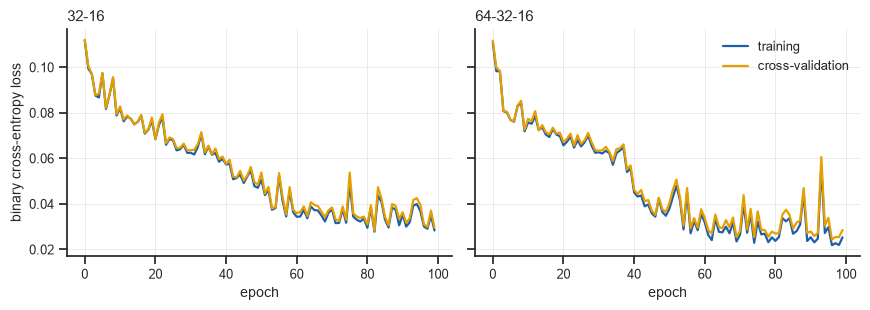

,train accuracy,CV accuracy,majority baseline (CV)
model,,,
32-16,0.988,0.987,0.647
64-32-16,0.989,0.988,0.647


In [22]:
import torch
import esc_ml as ml

features = df[esc.ESC_PARAMS].copy()
features['log10gain'] = np.log10(df['optimizer_gain'])
features['sinfre'] = np.sin(df['dither_frequency'])
features['product'] = df['optimizer_gain'] * df['dither_amplitude'] * features['sinfre']
features[['n_D_decay_rate', 'n_T_decay_rate']] = df[['n_D_decay_rate', 'n_T_decay_rate']]   # the plant differs per run
data = ml.split_data(features, df['converged'])

torch.manual_seed(1)   # reproducible initial weights
models = {'32-16': ml.make_model(features.shape[1], hidden=(32, 16)),
          '64-32-16': ml.make_model(features.shape[1], hidden=(64, 32, 16))}
histories = {name: ml.train_classifier(model, data['X_train'], data['y_train'], data['X_cv'], data['y_cv'],
                                       epochs=100, batch_size=1000)
             for name, model in models.items()}

esc.loss_curves(histories)
plt.show()
ml.summary_table(models, data)

Confusion matrix of the better model, and where it goes wrong: the table gives the median of each feature for
the correct predictions, the false positives (predicted to converge, did not) and the false negatives.

In [23]:
best = max(models, key=lambda name: ml.accuracy(models[name], data['X_cv'], data['y_cv']))
ml.report(models[best], data['X_cv'], data['y_cv'], title=f'Model {best} on the cross-validation set')
ml.error_table(models[best], data['X_cv'], data['y_cv']).round(4)

Model 64-32-16 on the cross-validation set: accuracy 0.988 (majority baseline 0.647)
confusion matrix [rows: true 0/1, columns: predicted 0/1]
[[25564   329]
 [  158 13949]]
              precision    recall  f1-score   support

           0      0.994     0.987     0.991     25893
           1      0.977     0.989     0.983     14107

    accuracy                          0.988     40000
   macro avg      0.985     0.988     0.987     40000
weighted avg      0.988     0.988     0.988     40000



,correct,false negative,false positive
optimizer_gain,0.0069,0.4019,0.0849
dither_amplitude,0.4979,0.7847,0.2585
dither_frequency,5.0270,3.9436,3.6015
log10gain,-2.1633,-0.3964,-1.0709
sinfre,0.3228,0.1256,0.3742
product,0.0000,0.0008,0.0003
n_D_decay_rate,0.5847,0.5733,0.5876
n_T_decay_rate,0.6019,0.6066,0.6041
number of runs,39513.0000,158.0000,329.0000


## Notes

- **Why this dataset was regenerated.** The earlier sweep (10k runs) came from a version of
  `STO_ESC_randdecay.m` in which deuterium and tritium fuelling were swapped, so the controller converged to
  $1 - r_\mathrm{ideal}$ while convergence was checked against $r_\mathrm{ideal}$. It also did not store the
  loss rates of each run. That data and its notebook were removed (they are still in the git history).
- The MATLAB script is corrected as well and now stores the loss rates, but it has not been re-run.
  `generate_STO_random_decay.py` produces the same experiment with the validated Python simulator.
- Random loss rates change little for small and moderate dither amplitudes. The lower convergence fraction comes
  from large amplitudes combined with an ideal ratio away from 0.5 (Section 5). In those runs $\hat r$ is biased,
  so "not converged" does not necessarily mean that the plasma is far from its optimum.